In [64]:
import pandas as pd

df = pd.read_excel("../data/raw/DATA RUMAH.xlsx")
df.head()


,NO,NAMA RUMAH,HARGA,LB,LT,KT,KM,GRS
0,1,"Rumah Murah Hook Tebet Timur, Tebet, Jakarta S...",3800000000,220,220,3,3,0
1,2,"Rumah Modern di Tebet dekat Stasiun, Tebet, Ja...",4600000000,180,137,4,3,2
2,3,"Rumah Mewah 2 Lantai Hanya 3 Menit Ke Tebet, T...",3000000000,267,250,4,4,4
3,4,"Rumah Baru Tebet, Tebet, Jakarta Selatan",430000000,40,25,2,2,0
4,5,"Rumah Bagus Tebet komp Gudang Peluru lt 350m, ...",9000000000,400,355,6,5,3


In [65]:
df.shape

(1010, 8)

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   NO          1010 non-null   int64
 1   NAMA RUMAH  1010 non-null   str  
 2   HARGA       1010 non-null   int64
 3   LB          1010 non-null   int64
 4   LT          1010 non-null   int64
 5   KT          1010 non-null   int64
 6   KM          1010 non-null   int64
 7   GRS         1010 non-null   int64
dtypes: int64(7), str(1)
memory usage: 63.3 KB


In [67]:
df.describe()

,NO,HARGA,LB,LT,KT,KM,GRS
count,1010.000000,1.010000e+03,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000
mean,505.500000,7.628987e+09,276.539604,237.432673,4.668317,3.607921,1.920792
std,291.706188,7.340946e+09,177.864557,179.957604,1.572776,1.420066,1.510998
min,1.000000,4.300000e+08,40.000000,25.000000,2.000000,1.000000,0.000000
25%,253.250000,3.262500e+09,150.000000,130.000000,4.000000,3.000000,1.000000
50%,505.500000,5.000000e+09,216.500000,165.000000,4.000000,3.000000,2.000000
75%,757.750000,9.000000e+09,350.000000,290.000000,5.000000,4.000000,2.000000
max,1010.000000,6.500000e+10,1126.000000,1400.000000,10.000000,10.000000,10.000000


In [68]:
df.isnull().sum()

NO            0
NAMA RUMAH    0
HARGA         0
LB            0
LT            0
KT            0
KM            0
GRS           0
dtype: int64

In [69]:
df = df.rename(columns={
    "NO" : "no",
    "NAMA RUMAH": "nama_rumah",
    "HARGA": "harga",
    "LB": "luas_bangunan",
    "LT": "luas_tanah",
    "KT": "kamar_tidur",
    "KM": "kamar_mandi",
    "GRS": "kapasitas_garasi",
})
df.head()

,no,nama_rumah,harga,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,kapasitas_garasi
0,1,"Rumah Murah Hook Tebet Timur, Tebet, Jakarta S...",3800000000,220,220,3,3,0
1,2,"Rumah Modern di Tebet dekat Stasiun, Tebet, Ja...",4600000000,180,137,4,3,2
2,3,"Rumah Mewah 2 Lantai Hanya 3 Menit Ke Tebet, T...",3000000000,267,250,4,4,4
3,4,"Rumah Baru Tebet, Tebet, Jakarta Selatan",430000000,40,25,2,2,0
4,5,"Rumah Bagus Tebet komp Gudang Peluru lt 350m, ...",9000000000,400,355,6,5,3


In [70]:
df.isnull().sum()

no                  0
nama_rumah          0
harga               0
luas_bangunan       0
luas_tanah          0
kamar_tidur         0
kamar_mandi         0
kapasitas_garasi    0
dtype: int64

In [71]:
kolom = [c for c in df.columns if c != "no"]
df[df.duplicated(subset=kolom, keep=False)]

,no,nama_rumah,harga,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,kapasitas_garasi
116,117,Rumah Lama Tebet Timur,4000000000,200,146,3,1,1
125,126,"Di Kebun Baru Rumah Terawat, Area Strategis",4000000000,139,230,4,4,1
275,276,Rumah Lama Tebet Timur,4000000000,200,146,3,1,1
1007,1008,"Di Kebun Baru Rumah Terawat, Area Strategis",4000000000,139,230,4,4,1


In [72]:
print("Sebelum menghapus duplikat, jumlah data: ", df.shape)
df = df.drop_duplicates(subset=kolom).reset_index(drop=True)
print("Setelah menghapus duplikat, jumlah data: ", df.shape)

Sebelum menghapus duplikat, jumlah data:  (1010, 8)
Setelah menghapus duplikat, jumlah data:  (1008, 8)


In [73]:
df.sort_values("harga", ascending=False).head(10)

,no,nama_rumah,harga,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,kapasitas_garasi
282,284,Dijual Rumah Mnmls Ada Mini Swpool Tebet Jaksel,65000000000,300,200,5,7,4
469,471,Rumah Tua HITUNG TANAH TERMURAH di Area Komers...,55000000000,400,1075,4,3,4
473,475,"Rumah Lama Di Prime Area Tebet, Komersial",55000000000,1126,1224,4,4,2
122,123,Rumah baru lux furnish di kawasan elit tebet j...,42000000000,850,600,5,5,5
750,752,House In Dukuh Patra,42000000000,600,624,3,3,2
31,32,Rumah Mewah Furnished Tebet Barat Swimming Pol...,42000000000,900,600,7,7,1
50,51,"Rumah baru & mewah di Tebet Jaksel, Tebet, Jak...",41000000000,850,600,7,7,0
219,220,Dijual Cepat Rumah Bagus Di Tebet,38000000000,500,720,6,6,3
515,517,"For Sale British Tuscan House At Tebet Mas, Ja...",37000000000,500,720,5,5,2
566,568,"Rumah tebet dalam, jalan 3 mobil, lingkungan t...",35000000000,1000,1400,10,7,7


In [74]:
df["harga_per_m2"] = df["harga"] / df["luas_bangunan"]
df["harga_per_m2"].describe()

count    1.008000e+03
mean     2.650212e+07
std      1.510036e+07
min      2.604167e+06
25%      1.791118e+07
50%      2.222222e+07
75%      3.000000e+07
max      2.166667e+08
Name: harga_per_m2, dtype: float64

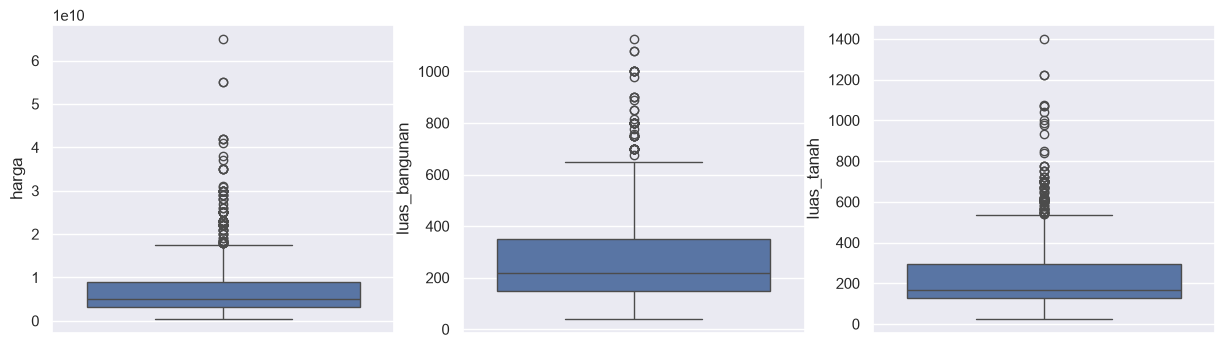

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df["harga"], ax=axes[0])
sns.boxplot(y=df["luas_bangunan"], ax=axes[1])
sns.boxplot(y=df["luas_tanah"], ax=axes[2])
plt.show()


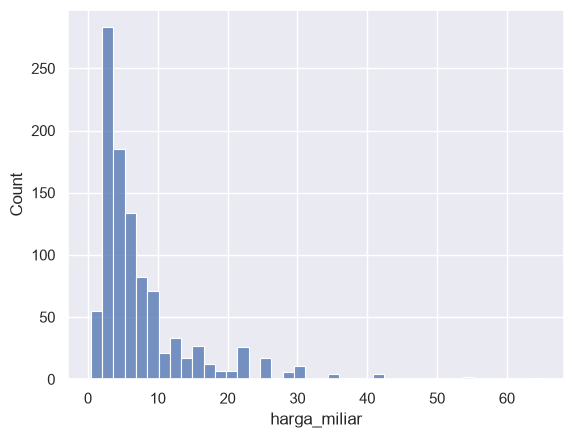

In [76]:
df["harga_miliar"] = df["harga"] / 1_000_000_000

sns.histplot(df["harga_miliar"], bins=40)
plt.show()

In [77]:
df["harga_per_m2"] = df["harga"] / df["luas_bangunan"]

df.sort_values("harga_per_m2", ascending=False).head(10)

,no,nama_rumah,harga,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,kapasitas_garasi,harga_per_m2,harga_miliar
282,284,Dijual Rumah Mnmls Ada Mini Swpool Tebet Jaksel,65000000000,300,200,5,7,4,2.166667e+08,65.000000
469,471,Rumah Tua HITUNG TANAH TERMURAH di Area Komers...,55000000000,400,1075,4,3,4,1.375000e+08,55.000000
531,533,Dijual Rumah Lux Tebet Jakarta Selatan,16000000000,140,246,6,6,1,1.142857e+08,16.000000
741,743,RUMAH MEWAH CANTIK SIAP HUNI DI MENTENG DALAM ...,18000000000,200,251,5,3,3,9.000000e+07,18.000000
816,818,Dijual rumah di Tebet,18000000000,200,450,5,3,2,9.000000e+07,18.000000
18,19,RUMAH MEWAH CANTIK DI MENTENG DALAM TEBET JAKA...,18000000000,200,251,5,3,3,9.000000e+07,18.000000
934,936,"5 Bedrooms House Tebet, Jakarta Selatan, DKI J...",35000000000,400,600,5,3,4,8.750000e+07,35.000000
488,490,Dijual Rumah Di Asem Barus Tebet,27000000512,350,1069,4,4,5,7.714286e+07,27.000001
219,220,Dijual Cepat Rumah Bagus Di Tebet,38000000000,500,720,6,6,3,7.600000e+07,38.000000
625,627,Rumah Siap Huni Dan Tanah Kosong Tebet Barat,15000000000,200,385,5,5,0,7.500000e+07,15.000000


In [78]:
df.sort_values("harga_per_m2").head(10)

,no,nama_rumah,harga,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,kapasitas_garasi,harga_per_m2,harga_miliar
418,420,"Dijual Rumah Elite di Tebet, Jakarta Selatan",1250000000,480,312,4,2,1,2.604167e+06,1.25
461,463,Dijual Rumah 3 Lantai Cocok Untuk Tempat Tingg...,1300000000,332,125,7,7,0,3.915663e+06,1.30
601,603,Rumah Dijual Murah Lokasi Strategis Di Kebon B...,1000000000,140,128,5,3,1,7.142857e+06,1.00
898,900,Rumah Minimalis di Tebet,950000000,130,92,4,2,0,7.307692e+06,0.95
314,316,Rumah Bagus Murah Sekali Cocok Utk Tempat Ting...,1500000000,200,170,7,2,0,7.500000e+06,1.50
754,756,Di Jual Rumah Murah Di Tebet,1500000000,200,170,7,2,0,7.500000e+06,1.50
802,804,Rumah Tebet Jakarta Selatan,750000000,100,78,3,1,0,7.500000e+06,0.75
994,996,Rumah Murah Sekali Siap Huni Akses Gg 2 Motor ...,1500000000,200,170,7,2,0,7.500000e+06,1.50
204,205,Rumah Murah Siap Huni di Jl. Palbatu III Tebet,690000000,90,50,3,1,0,7.666667e+06,0.69
565,567,"Tebet rumah modern classic, jakarta selatan",3500000000,400,150,5,4,2,8.750000e+06,3.50


In [79]:
# 1. Buang data yang janggal (kemungkinan salah input harga)
no_janggal  = [284, 420]
df = df[~df["no"].isin(no_janggal)]

# 2. cek duplikat berdasarkan spesifikasi 
kolom_spek = ["harga", "luas_bangunan", "luas_tanah", "kamar_tidur", "kamar_mandi", "kapasitas_garasi"]

dup = df[df.duplicated(subset=kolom_spek, keep=False)].sort_values("harga")
display(dup[["no", "nama_rumah"] + kolom_spek])

,no,nama_rumah,harga,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,kapasitas_garasi
314,316,Rumah Bagus Murah Sekali Cocok Utk Tempat Ting...,1500000000,200,170,7,2,0
754,756,Di Jual Rumah Murah Di Tebet,1500000000,200,170,7,2,0
994,996,Rumah Murah Sekali Siap Huni Akses Gg 2 Motor ...,1500000000,200,170,7,2,0
391,393,Rumah Siap Huni Hanya 50m Dari Dan Ke Asem Bar...,2100000000,100,126,2,2,1
988,990,Rumah Siap Huni Hanya 50meter Ke Jalan Asembar...,2100000000,100,126,2,2,1
...,...,...,...,...,...,...,...,...
323,325,Dijual Rumah Second Strategis Tanah Luas di Tebet,23000000000,350,565,5,3,4
408,410,Rumah Second Terawat Dan Setrategis Tebet Jaka...,23000000000,350,565,5,3,4
54,55,"Rumah di tebet, Jakarta Selatan, dekat tol, Te...",23000000000,750,610,8,6,4
281,283,Dijual Rumah Secondary Luas di tebent Lokasi S...,23000000000,350,565,5,3,4


In [80]:
dup = df[df.duplicated(subset=kolom_spek, keep=False)].copy()
dup["kelompok"] = dup.groupby(kolom_spek).ngroup()
dup = dup.sort_values("kelompok")

dup[["kelompok", "no", "nama_rumah"] + kolom_spek]

,kelompok,no,nama_rumah,harga,luas_bangunan,luas_tanah,kamar_tidur,kamar_mandi,kapasitas_garasi
314,0,316,Rumah Bagus Murah Sekali Cocok Utk Tempat Ting...,1500000000,200,170,7,2,0
754,0,756,Di Jual Rumah Murah Di Tebet,1500000000,200,170,7,2,0
994,0,996,Rumah Murah Sekali Siap Huni Akses Gg 2 Motor ...,1500000000,200,170,7,2,0
391,1,393,Rumah Siap Huni Hanya 50m Dari Dan Ke Asem Bar...,2100000000,100,126,2,2,1
988,1,990,Rumah Siap Huni Hanya 50meter Ke Jalan Asembar...,2100000000,100,126,2,2,1
...,...,...,...,...,...,...,...,...,...
281,34,283,Dijual Rumah Secondary Luas di tebent Lokasi S...,23000000000,350,565,5,3,4
323,34,325,Dijual Rumah Second Strategis Tanah Luas di Tebet,23000000000,350,565,5,3,4
408,34,410,Rumah Second Terawat Dan Setrategis Tebet Jaka...,23000000000,350,565,5,3,4
54,35,55,"Rumah di tebet, Jakarta Selatan, dekat tol, Te...",23000000000,750,610,8,6,4


In [81]:
sebelum = len(df)
df = df.drop_duplicates(subset=kolom_spek).reset_index(drop=True)
print(f"Dihapus: {sebelum - len(df)} baris, tersisa: {len(df)}")

Dihapus: 41 baris, tersisa: 965


In [82]:
df.to_csv("../data/processed/data_rumah_bersih.csv", index=False)

## EDA (Exploratory Data Analysis)

In [83]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

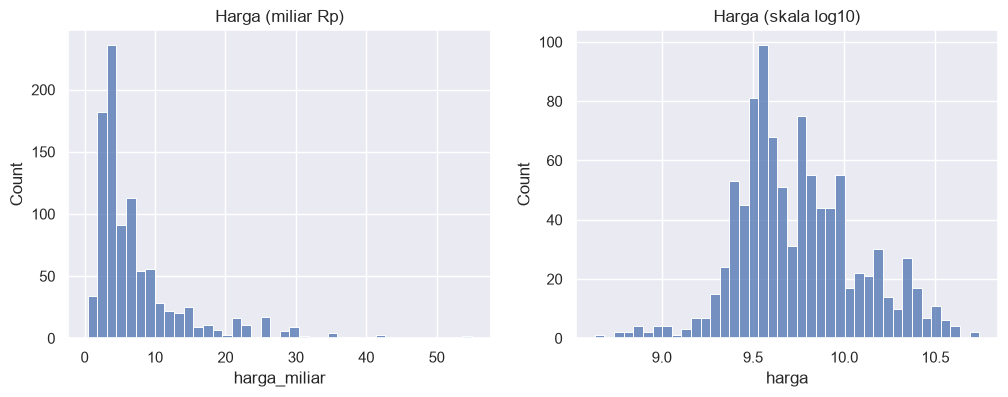

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["harga_miliar"], bins=40, ax=axes[0])
axes[0].set_title("Harga (miliar Rp)")

sns.histplot(np.log10(df["harga"]), bins=40, ax=axes[1])
axes[1].set_title("Harga (skala log10)")

plt.show()

In [85]:
# Mencari fitur mana yang paling berhubungan dengan harga rumah.
kolom_angka = ["harga", "luas_bangunan", "luas_tanah", "kamar_tidur", "kamar_mandi", "kapasitas_garasi"]

df[kolom_angka].corr()["harga"].sort_values(ascending=False)

harga               1.000000
luas_tanah          0.836724
luas_bangunan       0.774968
kapasitas_garasi    0.482851
kamar_mandi         0.404606
kamar_tidur         0.338245
Name: harga, dtype: float64

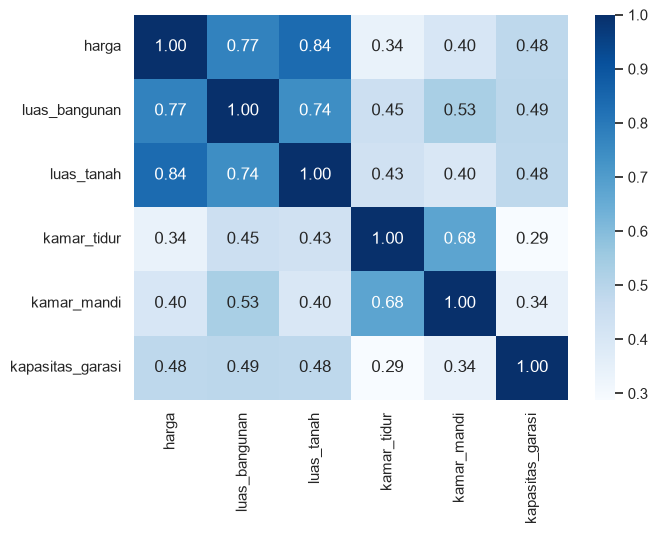

In [86]:
# Bentuk heatmap untuk melihat korelasi antar fitur numerik.
plt.figure(figsize=(7, 5))
sns.heatmap(df[kolom_angka].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.show()

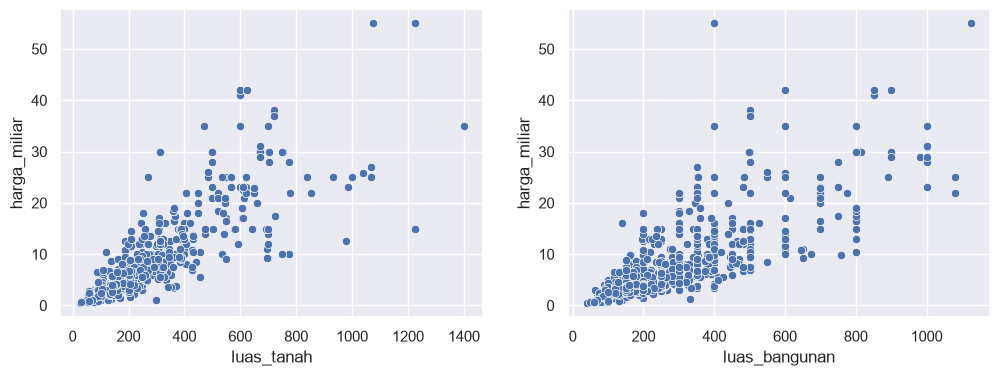

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(data=df, x="luas_tanah", y="harga_miliar", ax=axes[0])
sns.scatterplot(data=df, x="luas_bangunan", y="harga_miliar", ax=axes[1])

plt.show()

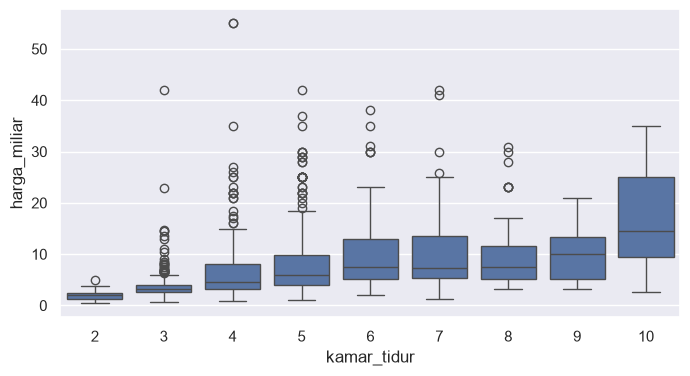

In [88]:
# Pengaruh jumlah kamar tidur dengan harga rumah
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="kamar_tidur", y="harga_miliar")
plt.show()


## Training first model


#### Menentukan fitur (X) dan target (Y)

In [89]:
fitur = ["luas_bangunan", "luas_tanah", "kamar_tidur", "kamar_mandi", "kapasitas_garasi"]

X = df[fitur]
y = df["harga"]

#### Split data menjadi data latih dan data uji


In [90]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test  = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(772, 5) (193, 5)


#### Melatih model regresi linear

In [91]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)


#### Ukur seberapa bagus hasil testing modelnya

In [92]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

print(f"MAE: Rp{mae/1e9:.2f} miliar")
print(f"R²: {r2:.3f}")

MAE: Rp2.35 miliar
R²: 0.735


In [93]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

mae_dummy = mean_absolute_error(y_test, dummy.predict(X_test))
print(f"MAE tebakan rata-rata: Rp{mae_dummy/1e9:.2f} miliar")

MAE tebakan rata-rata: Rp5.42 miliar


## Random Forest Model

In [94]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train);

## Bandingkan dari ketiga model dalam satu tabel

In [95]:
from sklearn.metrics import mean_absolute_error, r2_score

hasil = {}
for nama, m in [("Tebakan rata-rata", dummy), ("Linear Regression", model), ("Random Forest", rf)]:
    p = m.predict(X_test)
    hasil[nama] = {
        "MAE (miliar Rp)": mean_absolute_error(y_test, p) / 1e9,
        "R²": r2_score(y_test, p),
    }

pd.DataFrame(hasil).T.round(3)

,MAE (miliar Rp),R²
Tebakan rata-rata,5.424,-0.011
Linear Regression,2.353,0.735
Random Forest,1.731,0.830


## Lihat tebakan vs harga sebenarnya

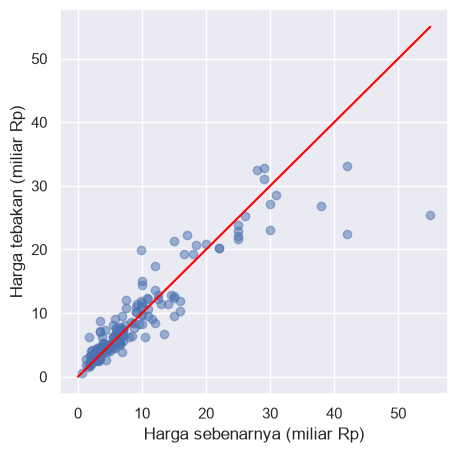

In [96]:
import matplotlib.pyplot as plt

pred_rf = rf.predict(X_test)
maks = max(y_test.max(), pred_rf.max()) / 1e9

plt.figure(figsize=(5, 5))
plt.scatter(y_test / 1e9, pred_rf / 1e9, alpha=0.5)
plt.plot([0, maks], [0, maks], color="red")
plt.xlabel("Harga sebenarnya (miliar Rp)")
plt.ylabel("Harga tebakan (miliar Rp)")
plt.show()

## Fitur paling berpengaruh

In [97]:
pd.Series(rf.feature_importances_, index=fitur).sort_values(ascending=False)

luas_tanah          0.774846
luas_bangunan       0.144303
kamar_mandi         0.028025
kapasitas_garasi    0.027682
kamar_tidur         0.025143
dtype: float64

## Cross-Validation

In [98]:
from sklearn.model_selection import cross_val_score

skor = cross_val_score(rf, X, y, cv=5, scoring="neg_mean_absolute_error")
print("MAE tiap lipatan (miliar Rp):", (-skor / 1e9).round(2))
print("Rata-rata:", round(-skor.mean() / 1e9, 2))

MAE tiap lipatan (miliar Rp): [1.83 1.5  2.01 1.98 1.58]
Rata-rata: 1.78
